# Are the 14 yearly differences independent?

**Why.** The significance test (`analysis/stats.py`) is a two-sided one-sample *t*-test of the 14 paired yearly differences (2001–2014) in each cell, then Benjamini–Hochberg FDR (α = 0.10, cells ≥ 45°N). The *t*-test assumes the 14 differences are independent. If year *y* + 1 remembers year *y* (slow land memory: soil water, snow, vegetation; or drift), the effective sample size is smaller and the test is too permissive. The methods outline (`methods-claude.tex`, Statistics) asks for one line on this.

**Test.** For each contrast and field, the lag-1 autocorrelation *r*₁ of the yearly differences *d*(*y*) = case1(*y*) − case2(*y*):

1. **Regional means** (≥ 45°N, modified cells): *r*₁ (and *r*₂) of the 14-value series, compared with the white-noise null distribution for *n* = 14 (Monte Carlo). Effective sample size *n*ₑ = *n* (1 − *r*₁)/(1 + *r*₁) (Bretherton et al. 1999), *r*₁ clipped at 0.
2. **Cell by cell** (≥ 45°N): distribution of *r*₁ over the cells against the same null; share of cells outside the null 95 % range (5 % expected if independent).
3. **Effect on the maps:** number of FDR-significant cells with the plain *t*-test vs a *t*-test whose variance is inflated by (1 + *r*)/(1 − *r*) and with *n*ₑ − 1 degrees of freedom, *r* = pooled cell-mean *r*₁ + 1/*n* (bias correction for short series, conservative), clipped at 0.

**Note.** With *n* = 14 one *r*₁ is very noisy (null 95 % range ≈ ±0.5) and biased low (mean ≈ −1/*n*). The pooled numbers (regional, cell distribution) carry the information, single cells do not.

**Runs.** The postprocessed files in `data/processed-data/postprocessing/` (2001–2014), contrasts from `forcing_maps.budget_contrasts` (LCC − CTRL, LCC − LCC_fBVOC, CTRL_FUT − CTRL_PD). Contrasts with a missing file are skipped and listed. The case name of each file is printed in step 0.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1] / "src"))   # repo src/, no pip install needed

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.analysis.stats import cellwise_pvalue, fdr_mask

set_default_style()
START_YEAR, END_YEAR = 2001, 2014
N = END_YEAR - START_YEAR + 1
LAT_MIN = 45.0
FDR_ALPHA = 0.10
OUT = Path("yearly_difference_autocorrelation_outputs")
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

# (class, field, units): Ghan NET terms, temperature, emissions, SOA, cloud. All CAM (atm) fields.
FIELDS = [("RADIATIVE", "NET_toa", "W m-2"), ("RADIATIVE", "NET_dir", "W m-2"),
          ("RADIATIVE", "NET_cloud", "W m-2"), ("RADIATIVE", "NET_rest", "W m-2"),
          ("METEO", "TREFHT", "K"),
          ("BVOC", "SFISOP_mgm2d", "mg m-2 d-1"), ("BVOC", "SFMTERP_mgm2d", "mg m-2 d-1"),
          ("SOA", "cbSOA_mgm2", "mg m-2"),
          ("CLOUDPROP", "ACTNL_incld", "cm-3"), ("CLOUDPROP", "TGCLDLWP_gm2", "g m-2")]
CONTRASTS = [(p, *row) for p in fm.BVOC_PAIRS for row in fm.budget_contrasts(p)]   # (period, label, case1, case2)
CONTRASTS

[('PD', 'LCC − CTRL', 'LCC_PD', 'CTRL_PD'),
 ('PD', 'LCC − LCC_fBVOC', 'LCC_PD', 'LCC_PD_fBVOCctrlPD'),
 ('FUT', 'LCC − CTRL', 'LCC_FUT', 'CTRL_FUT'),
 ('FUT', 'LCC − LCC_fBVOC', 'LCC_FUT', 'LCC_FUT_fBVOCctrlPD'),
 ('FUT', 'CTRL_FUT − CTRL_PD', 'CTRL_FUT', 'CTRL_PD')]

## 0. Files and case names

In [2]:
import netCDF4
aliases = sorted({c for _, _, c1, c2 in CONTRASTS for c in (c1, c2)})
have = {}
for a in aliases:
    p = fm.filename(a, "RADIATIVE", START_YEAR, END_YEAR)
    have[a] = p.exists()
    case = netCDF4.Dataset(p).getncattr("casename") if p.exists() else "MISSING"
    print(f"{a:28s} {case}")
CONTRASTS = [c for c in CONTRASTS if have[c[2]] and have[c[3]]]
print("\nContrasts used:")
for c in CONTRASTS:
    print("  ", c)

CTRL_FUT                     NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028


CTRL_PD                      NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029


LCC_FUT                      NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028


LCC_FUT_fBVOCctrlPD          NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-20261031


LCC_PD                       NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028
LCC_PD_fBVOCctrlPD           MISSING

Contrasts used:
   ('PD', 'LCC − CTRL', 'LCC_PD', 'CTRL_PD')
   ('FUT', 'LCC − CTRL', 'LCC_FUT', 'CTRL_FUT')
   ('FUT', 'LCC − LCC_fBVOC', 'LCC_FUT', 'LCC_FUT_fBVOCctrlPD')
   ('FUT', 'CTRL_FUT − CTRL_PD', 'CTRL_FUT', 'CTRL_PD')


## 1. White-noise null for *r*₁ with *n* = 14

Same estimator as for the data: *r*₁ = Σ (*d*ₜ − *d̄*)(*d*ₜ₊₁ − *d̄*) / Σ (*d*ₜ − *d̄*)².

In [3]:
def detrend(x, axis=0):
    "Remove the least-squares linear trend along axis (NaN-free input)."
    x = np.moveaxis(np.asarray(x, float), axis, 0)
    t = np.arange(x.shape[0]) - (x.shape[0] - 1) / 2
    b = np.tensordot(t, x - x.mean(0), axes=(0, 0)) / (t**2).sum()
    return x - x.mean(0) - np.multiply.outer(t, b)

def lag_r(x, lag=1, axis=0):
    x = np.moveaxis(np.asarray(x, float), axis, 0)
    a = x - np.nanmean(x, axis=0)
    den = np.nansum(a**2, axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, np.nansum(a[lag:] * a[:-lag], axis=0) / den, np.nan)

rng = np.random.default_rng(0)
NULL = lag_r(rng.standard_normal((N, 200_000)))
NULL_LO, NULL_HI = np.quantile(NULL, [0.025, 0.975])
print(f"white noise, n = {N}: mean r1 = {NULL.mean():+.3f} (≈ -1/n = {-1/N:+.3f}), "
      f"95 % range [{NULL_LO:+.2f}, {NULL_HI:+.2f}]")

def p_null(r):
    "Two-sided p of r1 under white noise (Monte Carlo)."
    return 2 * min((NULL <= r).mean(), (NULL >= r).mean())

def n_eff(r):
    r = max(r, 0.0)
    return N * (1 - r) / (1 + r)

white noise, n = 14: mean r1 = -0.071 (≈ -1/n = -0.071), 95 % range [-0.52, +0.40]


## 2. Yearly differences

In [4]:
def field_ok(ds, field):
    if field == "cbSOA_mgm2":
        return "cb_SOA_A1" in ds
    return field in fm.YEARLY_DERIVED or field in ds

D = {}   # (period, label, field) -> (year, lat, lon) differences
for period, label, c1, c2 in CONTRASTS:
    for cls, field, _ in FIELDS:
        ds1, ds2 = (fm.open_class(c, cls, START_YEAR, END_YEAR) for c in (c1, c2))
        f = field if field_ok(ds1, field) and field_ok(ds2, field) else None
        if f is None and field == "cbSOA_mgm2":
            f = "SOA_cb_mgm2"   # old-chain files
        if f is None:
            print("skip", period, label, field); continue
        D[(period, label, field)] = fm.yearly_difference(c1, c2, cls, f, START_YEAR, END_YEAR).load()
        assert D[(period, label, field)].sizes["year"] == N
print(len(D), "difference fields")
REF = fm.open_class(fm.BVOC_PAIRS["PD"]["ctrl"], "RADIATIVE", START_YEAR, END_YEAR)
MASKS = fm.region_masks(REF, lat_min=LAT_MIN)
REGIONS = [f"≥{LAT_MIN:g}°N", "modified cells"]

40 difference fields


## 3. Regional means: *r*₁, *r*₂, *n*ₑ

One series of 14 values per contrast, field and region. `p_r1` = two-sided white-noise p. `sig_t` = mean / standard error, plain *t*-test p, and the same p with *n*ₑ.

In [5]:
rows = []
for (period, label, field), d in D.items():
    for region in REGIONS:
        s = fm.regional(d, REF, MASKS[region]).values
        r1, r2 = float(lag_r(s, 1)), float(lag_r(s, 2))
        ne = n_eff(r1)
        se = s.std(ddof=1) / np.sqrt(N)
        t = s.mean() / se
        p_t = 2 * stats.t.sf(abs(t), N - 1)
        t_adj = s.mean() / (s.std(ddof=1) / np.sqrt(ne))
        p_adj = 2 * stats.t.sf(abs(t_adj), max(ne - 1, 1))
        tr = stats.linregress(np.arange(N), s)
        r1_dt = float(lag_r(s - (tr.intercept + tr.slope * np.arange(N)), 1))
        rows.append(dict(period=period, contrast=label, field=field, region=region, mean=s.mean(),
                         r1=r1, r2=r2, p_r1=p_null(r1), n_eff=ne, p_t=p_t, p_t_neff=p_adj,
                         trend_pct_per_decade=100 * 10 * tr.slope / abs(s.mean()) if s.mean() else np.nan,
                         p_trend=tr.pvalue, r1_detrended=r1_dt))
REG = pd.DataFrame(rows)
REG.to_csv(TAB / "regional_r1.csv", index=False)
pd.set_option("display.width", 200)
REG.round(3)

,period,contrast,field,region,mean,r1,r2,p_r1,n_eff,p_t,p_t_neff,trend_pct_per_decade,p_trend,r1_detrended
0,PD,LCC − CTRL,NET_toa,≥45°N,0.240,0.261,-0.352,0.173,8.204,0.000,0.000,14.234,0.354,0.209
1,PD,LCC − CTRL,NET_toa,modified cells,0.541,0.308,-0.150,0.116,7.399,0.000,0.000,10.755,0.224,0.290
2,PD,LCC − CTRL,NET_dir,≥45°N,-0.012,0.317,-0.376,0.108,7.261,0.004,0.042,-38.482,0.604,0.286
3,PD,LCC − CTRL,NET_dir,modified cells,-0.032,0.364,-0.366,0.069,6.531,0.000,0.001,-17.602,0.528,0.330
4,PD,LCC − CTRL,NET_cloud,≥45°N,-0.060,0.322,-0.208,0.103,7.181,0.000,0.012,23.660,0.659,0.299
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,FUT,CTRL_FUT − CTRL_PD,cbSOA_mgm2,modified cells,2.727,0.300,-0.206,0.125,7.532,0.000,0.000,8.289,0.010,-0.056
76,FUT,CTRL_FUT − CTRL_PD,ACTNL_incld,≥45°N,-10.958,-0.095,-0.213,0.928,14.000,0.000,0.000,0.829,0.804,-0.102
77,FUT,CTRL_FUT − CTRL_PD,ACTNL_incld,modified cells,-11.029,0.047,-0.180,0.628,12.733,0.000,0.000,-5.987,0.190,-0.057
78,FUT,CTRL_FUT − CTRL_PD,TGCLDLWP_gm2,≥45°N,12.219,-0.329,-0.119,0.291,14.000,0.000,0.000,-4.869,0.210,-0.370


In [6]:
print(f"Regional series: {len(REG)}")
print(f"  r1 median {REG.r1.median():+.2f}, range [{REG.r1.min():+.2f}, {REG.r1.max():+.2f}]")
print(f"  outside white-noise 95 % range: {(REG.p_r1 < 0.05).sum()} of {len(REG)} "
      f"(expected by chance ≈ {0.05 * len(REG):.1f})")
print(f"  r1 > {NULL_HI:.2f}: {(REG.r1 > NULL_HI).sum()}")
flip = REG[(REG.p_t < 0.05) != (REG.p_t_neff < 0.05)]
print(f"  regional means whose 5 % significance changes with n_eff: {len(flip)}")
flip.round(3)

Regional series: 80
  r1 median +0.12, range [-0.41, +0.75]
  outside white-noise 95 % range: 6 of 80 (expected by chance ≈ 4.0)
  r1 > 0.40: 6
  regional means whose 5 % significance changes with n_eff: 3


,period,contrast,field,region,mean,r1,r2,p_r1,n_eff,p_t,p_t_neff,trend_pct_per_decade,p_trend,r1_detrended
12,PD,LCC − CTRL,SFMTERP_mgm2d,≥45°N,0.002,0.748,0.489,0.000,2.017,0.001,0.356,-183.918,0.000,0.101
13,PD,LCC − CTRL,SFMTERP_mgm2d,modified cells,0.003,0.638,0.423,0.001,3.095,0.003,0.218,-189.441,0.001,-0.003
33,FUT,LCC − CTRL,SFMTERP_mgm2d,modified cells,-0.011,0.204,0.163,0.261,9.254,0.021,0.064,-194.064,0.033,-0.176


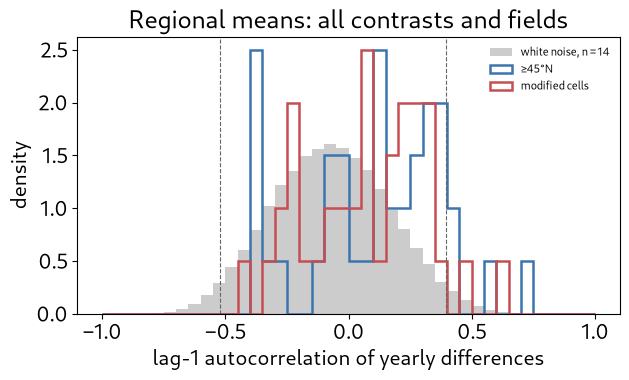

In [7]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(-1, 1, 41)
ax.hist(NULL, bins=bins, density=True, color="0.8", label=f"white noise, n = {N}")
for region, c in zip(REGIONS, ["#2C3990", "#BC423E"]):
    ax.hist(REG.loc[REG.region == region, "r1"], bins=bins, density=True, histtype="step", lw=1.8,
            color=c, label=region)
for q in (NULL_LO, NULL_HI):
    ax.axvline(q, color="0.4", ls="--", lw=0.8)
ax.set(xlabel="lag-1 autocorrelation of yearly differences", ylabel="density",
       title="Regional means: all contrasts and fields")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "regional_r1_hist.png", dpi=200, bbox_inches="tight")

### 3b. Memory or trend?

A positive *r*₁ can come from year-to-year memory (anomaly of year *y* persists into *y* + 1) or from a slow trend in the difference over 2001–2014 (one run still adjusting). A trend also gives positive *r*₂; memory alone decays. Below: series with *r*₁ above the null 95 % range or a trend with p < 0.05, with *r*₁ after removing the linear trend. Detrended *r*₁ of white noise is biased lower still (≈ −0.15 for *n* = 14), so compare with that.

In [8]:
NULL_DT = lag_r(detrend(rng.standard_normal((N, 100_000))))
print(f"white noise after detrending: mean r1 = {NULL_DT.mean():+.3f}, 95 % range "
      f"[{np.quantile(NULL_DT, 0.025):+.2f}, {np.quantile(NULL_DT, 0.975):+.2f}]")
cols = ["period", "contrast", "field", "region", "mean", "r1", "r2", "trend_pct_per_decade", "p_trend", "r1_detrended"]
REG.loc[(REG.r1 > NULL_HI) | (REG.p_trend < 0.05), cols].round(3)

white noise after detrending: mean r1 = -0.143, 95 % range [-0.58, +0.32]


,period,contrast,field,region,mean,r1,r2,trend_pct_per_decade,p_trend,r1_detrended
12,PD,LCC − CTRL,SFMTERP_mgm2d,≥45°N,0.002,0.748,0.489,-183.918,0.000,0.101
13,PD,LCC − CTRL,SFMTERP_mgm2d,modified cells,0.003,0.638,0.423,-189.441,0.001,-0.003
14,PD,LCC − CTRL,cbSOA_mgm2,≥45°N,0.001,0.356,-0.033,4288.853,0.020,-0.002
15,PD,LCC − CTRL,cbSOA_mgm2,modified cells,0.004,0.320,-0.074,581.892,0.026,-0.022
19,PD,LCC − CTRL,TGCLDLWP_gm2,modified cells,-0.322,0.286,0.114,-46.477,0.032,0.022
26,FUT,LCC − CTRL,NET_rest,≥45°N,0.235,0.449,0.346,-10.065,0.061,0.252
30,FUT,LCC − CTRL,SFISOP_mgm2d,≥45°N,0.014,-0.068,0.615,-71.648,0.007,-0.729
31,FUT,LCC − CTRL,SFISOP_mgm2d,modified cells,0.034,-0.243,0.462,-46.576,0.037,-0.594
32,FUT,LCC − CTRL,SFMTERP_mgm2d,≥45°N,-0.003,0.251,0.267,-356.901,0.014,-0.256
33,FUT,LCC − CTRL,SFMTERP_mgm2d,modified cells,-0.011,0.204,0.163,-194.064,0.033,-0.176


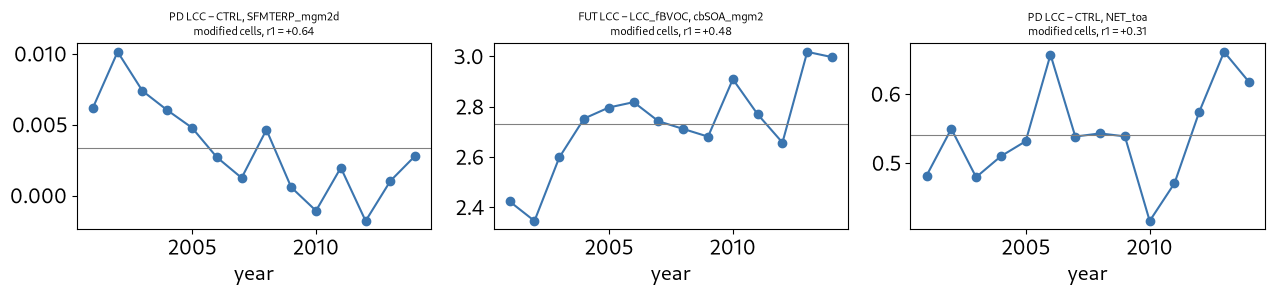

In [9]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (key, region) in zip(axes, [(("PD", fm.CONTRAST_LABELS["LCC-CTRL"], "SFMTERP_mgm2d"), "modified cells"),
                                    (("FUT", fm.CONTRAST_LABELS["LCC-fBVOC"], "cbSOA_mgm2"), "modified cells"),
                                    (("PD", fm.CONTRAST_LABELS["LCC-CTRL"], "NET_toa"), "modified cells")]):
    if key not in D:
        ax.axis("off"); continue
    s = fm.regional(D[key], REF, MASKS[region])
    ax.plot(s.year, s, "o-", color="#2C3990")
    ax.axhline(float(s.mean()), color="0.5", lw=0.8)
    ax.set_title(f"{key[0]} {key[1]}, {key[2]}\n{region}, r1 = {float(lag_r(s.values)):+.2f}", fontsize=8)
    ax.set_xlabel("year")
fig.tight_layout()
fig.savefig(FIG / "regional_series_examples.png", dpi=200, bbox_inches="tight")

## 4. Cell by cell (≥ 45°N)

Cells where the difference has no variance (e.g. emissions over ocean) are dropped. Neighbouring cells are correlated, so the "% outside" is indicative, not a formal test.

In [10]:
NORTH = MASKS[f"≥{LAT_MIN:g}°N"]
R1 = {}
rows = []
for key, d in D.items():
    r = xr.DataArray(lag_r(d.values), coords={"lat": d.lat, "lon": d.lon}, dims=("lat", "lon"))
    R1[key] = r
    v = r.where(NORTH).values.ravel()
    v_dt = lag_r(detrend(d.values)).ravel()[np.isfinite(v)]
    v = v[np.isfinite(v)]
    rows.append(dict(period=key[0], contrast=key[1], field=key[2], n_cells=v.size, mean_r1=v.mean(),
                     median_r1=np.median(v), pct_above=100 * (v > NULL_HI).mean(),
                     pct_below=100 * (v < NULL_LO).mean(), mean_r1_detrended=np.nanmean(v_dt)))
CELL = pd.DataFrame(rows)
CELL["pct_outside"] = CELL.pct_above + CELL.pct_below
CELL.to_csv(TAB / "cell_r1_summary.csv", index=False)
print(f"null: mean {NULL.mean():+.3f}, 2.5 % above and 2.5 % below")
CELL.round(3)

null: mean -0.071, 2.5 % above and 2.5 % below


,period,contrast,field,n_cells,mean_r1,median_r1,pct_above,pct_below,mean_r1_detrended,pct_outside
0,PD,LCC − CTRL,NET_toa,3456,-0.056,-0.059,2.344,2.025,-0.134,4.369
1,PD,LCC − CTRL,NET_dir,3456,-0.064,-0.050,2.083,2.546,-0.125,4.630
2,PD,LCC − CTRL,NET_cloud,3456,-0.077,-0.092,2.402,2.228,-0.146,4.630
3,PD,LCC − CTRL,NET_rest,3456,-0.017,-0.015,3.385,1.157,-0.103,4.543
4,PD,LCC − CTRL,TREFHT,3456,-0.020,-0.032,5.932,1.997,-0.102,7.928
5,PD,LCC − CTRL,SFISOP_mgm2d,1194,0.127,0.107,18.007,0.335,-0.007,18.342
6,PD,LCC − CTRL,SFMTERP_mgm2d,1194,0.291,0.302,42.462,0.419,0.076,42.881
7,PD,LCC − CTRL,cbSOA_mgm2,3456,0.322,0.338,12.124,0.000,-0.023,12.124
8,PD,LCC − CTRL,ACTNL_incld,3456,-0.072,-0.064,1.910,2.112,-0.143,4.022
9,PD,LCC − CTRL,TGCLDLWP_gm2,3456,-0.071,-0.074,2.459,2.170,-0.139,4.630


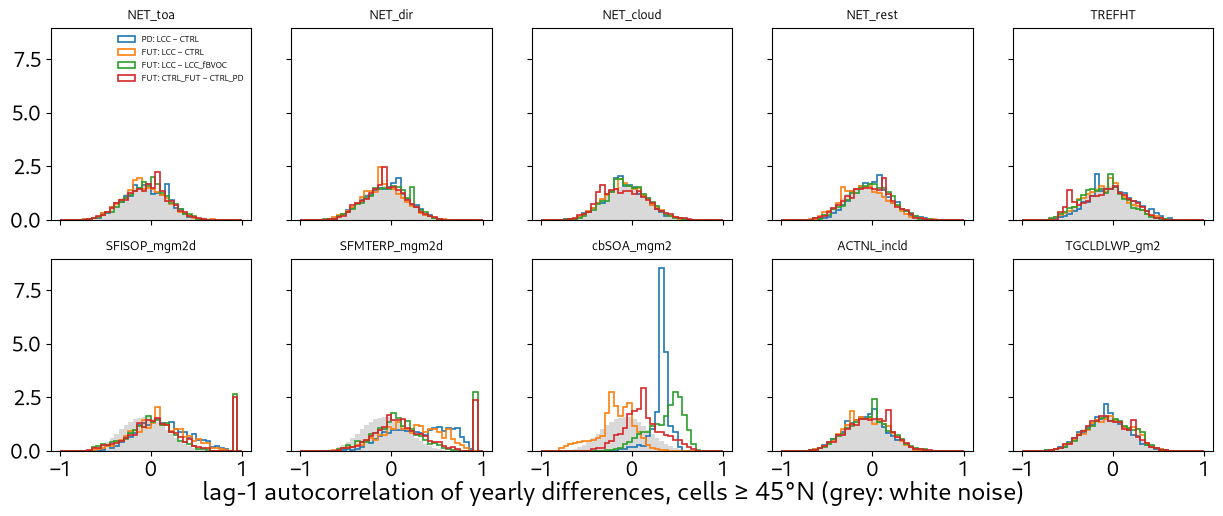

In [11]:
fields = [f for _, f, _ in FIELDS if any(k[2] == f for k in D)]
fig, axes = plt.subplots(2, (len(fields) + 1) // 2, figsize=(15, 5.5), sharex=True, sharey=True)
for ax, field in zip(axes.flat, fields):
    ax.hist(NULL, bins=bins, density=True, color="0.85")
    for key, r in R1.items():
        if key[2] == field:
            v = r.where(NORTH).values.ravel()
            ax.hist(v[np.isfinite(v)], bins=bins, density=True, histtype="step", lw=1.2,
                    label=f"{key[0]}: {key[1]}")
    ax.set_title(field, fontsize=9)
for ax in axes.flat[len(fields):]:
    ax.axis("off")
axes.flat[0].legend(frameon=False, fontsize=6)
fig.supxlabel("lag-1 autocorrelation of yearly differences, cells ≥ 45°N (grey: white noise)")
fig.savefig(FIG / "cell_r1_hist.png", dpi=200, bbox_inches="tight")

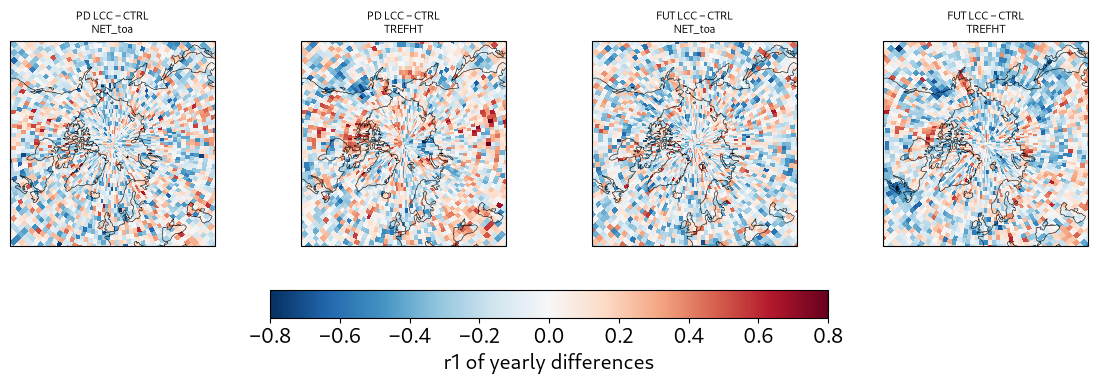

In [12]:
# map of r1 for the main contrasts, NET TOA and TREFHT
keys = [k for k in R1 if k[2] in ("NET_toa", "TREFHT") and k[1] == fm.CONTRAST_LABELS["LCC-CTRL"]]
proj = ccrs.NorthPolarStereo()
fig, axes = plt.subplots(1, len(keys), figsize=(3.6 * len(keys), 3.8), subplot_kw=dict(projection=proj))
for ax, k in zip(np.atleast_1d(axes), keys):
    ax.set_extent([-180, 180, LAT_MIN, 90], ccrs.PlateCarree())
    ax.coastlines(lw=0.4)
    m = ax.pcolormesh(R1[k].lon, R1[k].lat, R1[k], transform=ccrs.PlateCarree(), cmap="RdBu_r",
                      vmin=-0.8, vmax=0.8)
    ax.set_title(f"{k[0]} {k[1]}\n{k[2]}", fontsize=8)
fig.colorbar(m, ax=axes, orientation="horizontal", shrink=0.5, label="r1 of yearly differences",
             ticks=np.arange(-0.8, 0.81, 0.2))
fig.savefig(FIG / "cell_r1_maps.png", dpi=200, bbox_inches="tight")

## 5. Does it change the FDR stippling?

Plain test = `analysis.stats.cellwise_pvalue` (what the maps use). Adjusted test: variance × (1 + *r*)/(1 − *r*), *n*ₑ − 1 degrees of freedom, one *r* per contrast and field = max(0, pooled cell-mean *r*₁ + 1/*n*).

In [13]:
rows = []
for key, d in D.items():
    c = CELL.set_index(["period", "contrast", "field"]).loc[key]
    r = max(0.0, c.mean_r1 + 1 / N)
    ne = n_eff(r)
    mean, sd = d.mean("year"), d.std("year", ddof=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        t_adj = mean / (sd / np.sqrt(ne))
    p_adj = xr.apply_ufunc(lambda t: 2 * stats.t.sf(np.abs(t), max(ne - 1, 1)), t_adj)
    p = cellwise_pvalue(d)
    s0 = fdr_mask(p, FDR_ALPHA, within=NORTH)
    s1 = fdr_mask(p_adj, FDR_ALPHA, within=NORTH)
    n0, n1 = int(s0.sum()), int(s1.sum())
    rows.append(dict(period=key[0], contrast=key[1], field=key[2], r_used=r, n_eff=ne,
                     sig_plain=n0, sig_adjusted=n1, change_pct=100 * (n1 - n0) / n0 if n0 else np.nan))
FDR = pd.DataFrame(rows)
FDR.to_csv(TAB / "fdr_with_n_eff.csv", index=False)
FDR.round(2)

,period,contrast,field,r_used,n_eff,sig_plain,sig_adjusted,change_pct
0,PD,LCC − CTRL,NET_toa,0.01,13.59,754,735,-2.52
1,PD,LCC − CTRL,NET_dir,0.01,13.78,503,493,-1.99
2,PD,LCC − CTRL,NET_cloud,0.00,14.00,810,810,0.00
3,PD,LCC − CTRL,NET_rest,0.05,12.55,961,888,-7.60
4,PD,LCC − CTRL,TREFHT,0.05,12.62,2500,2415,-3.40
5,PD,LCC − CTRL,SFISOP_mgm2d,0.20,9.37,769,670,-12.87
6,PD,LCC − CTRL,SFMTERP_mgm2d,0.36,6.55,967,820,-15.20
7,PD,LCC − CTRL,cbSOA_mgm2,0.39,6.10,291,0,-100.00
8,PD,LCC − CTRL,ACTNL_incld,0.00,14.00,8,8,0.00
9,PD,LCC − CTRL,TGCLDLWP_gm2,0.00,13.99,343,343,0.00


## 6. Summary and the line for the methods

In [14]:
LAND = REG.field.isin(["SFISOP_mgm2d", "SFMTERP_mgm2d", "cbSOA_mgm2"])
def describe(t, what):
    print(f"{what}: {len(t)} series, median r1 {t.r1.median():+.2f}, {int((t.p_r1 < 0.05).sum())} outside the "
          f"white-noise 95 % range (≈ {0.05 * len(t):.1f} by chance); median detrended r1 {t.r1_detrended.median():+.2f}")
print(f"white noise n = {N}: mean r1 {NULL.mean():+.2f}, 95 % range [{NULL_LO:+.2f}, {NULL_HI:+.2f}]\n")
describe(REG[~LAND], "Regional, radiation / temperature / cloud")
describe(REG[LAND], "Regional, emissions and SOA burden")
cl = CELL.field.isin(["SFISOP_mgm2d", "SFMTERP_mgm2d", "cbSOA_mgm2"])
print(f"\nCells ≥ {LAT_MIN:g}°N, radiation / temperature / cloud: mean r1 {CELL[~cl].mean_r1.min():+.2f} to "
      f"{CELL[~cl].mean_r1.max():+.2f}, outside null range {CELL[~cl].pct_outside.min():.0f}–{CELL[~cl].pct_outside.max():.0f} %")
print(f"Cells ≥ {LAT_MIN:g}°N, emissions and SOA: mean r1 {CELL[cl].mean_r1.min():+.2f} to "
      f"{CELL[cl].mean_r1.max():+.2f}, outside null range {CELL[cl].pct_outside.min():.0f}–{CELL[cl].pct_outside.max():.0f} %; "
      f"after detrending mean r1 {CELL[cl].mean_r1_detrended.min():+.2f} to {CELL[cl].mean_r1_detrended.max():+.2f}")
fl = FDR.field.isin(["SFISOP_mgm2d", "SFMTERP_mgm2d", "cbSOA_mgm2"])
print(f"\nFDR cells with n_eff, radiation / temperature / cloud: change {FDR[~fl].change_pct.min():+.0f} to "
      f"{FDR[~fl].change_pct.max():+.0f} %")
print("FDR cells with n_eff, emissions and SOA:")
print(FDR[fl][["period", "contrast", "field", "r_used", "n_eff", "sig_plain", "sig_adjusted"]].round(2).to_string(index=False))

white noise n = 14: mean r1 -0.07, 95 % range [-0.52, +0.40]

Regional, radiation / temperature / cloud: 56 series, median r1 +0.09, 1 outside the white-noise 95 % range (≈ 2.8 by chance); median detrended r1 -0.02
Regional, emissions and SOA burden: 24 series, median r1 +0.21, 5 outside the white-noise 95 % range (≈ 1.2 by chance); median detrended r1 -0.00

Cells ≥ 45°N, radiation / temperature / cloud: mean r1 -0.10 to -0.02, outside null range 3–8 %
Cells ≥ 45°N, emissions and SOA: mean r1 -0.18 to +0.36, outside null range 8–53 %; after detrending mean r1 -0.40 to +0.08

FDR cells with n_eff, radiation / temperature / cloud: change -16 to +0 %
FDR cells with n_eff, emissions and SOA:
period           contrast         field  r_used  n_eff  sig_plain  sig_adjusted
    PD         LCC − CTRL  SFISOP_mgm2d    0.20   9.37        769           670
    PD         LCC − CTRL SFMTERP_mgm2d    0.36   6.55        967           820
    PD         LCC − CTRL    cbSOA_mgm2    0.39   6.10        

**Reading the result (2026-11-02 run; new-chain files; LCC_PD_fBVOCctrlPD not yet processed, so PD LCC − LCC_fBVOC is missing).**

- **Radiation (Ghan NET terms), TREFHT, CDNC, LWP:** the yearly differences behave like white noise. The cell-mean *r*₁ is close to the white-noise mean (−0.07), about 5 % of cells fall outside the null 95 % range (as expected), and the FDR stippling changes by at most a few percent with *n*ₑ. Treating the 14 years as independent is justified for these fields.
- **Emissions (SFISOP, SFMTERP) and SOA burden:** positive *r*₁ (cell-mean up to ≈ +0.3/+0.4, 12–53 % of cells outside the null range). §3b shows that this comes from **slow trends** in the difference over 2001–2014 (e.g. PD LCC − CTRL monoterpenes in the modified cells drift from ≈ +0.006–0.010 (2001–03) to ≈ 0 mg m⁻² d⁻¹ (2010–14), a small signal; FUT LCC − LCC_fBVOC SOA burden rises ≈ +13 % per decade). After detrending, the cell-mean *r*₁ drops to −0.10…+0.08. That is still above the detrended white-noise mean (−0.14), so there is some weak persistence left, strongest for FUT LCC − LCC_fBVOC SOA (+0.07), but most of the signal was the trend. A trend in the difference means one run is still adjusting (vegetation/LAI after the land spin-up, or prescribed-climatology vs interactive emissions). For the mean that is a question of **drift**, not of independence. Worth a look before the paper (b, inference).
- **Where *n*ₑ matters:** PD LCC − CTRL SOA burden (mean ≈ 0.004 mg m⁻² in the modified cells, near zero) loses all 291 FDR cells with *n*ₑ ≈ 6. PD LCC − CTRL monoterpenes (regional) are no longer significant with *n*ₑ ≈ 2–3. Both are tiny signals: report them as not robust. The large contrasts (FUT LCC − LCC_fBVOC, CTRL_FUT − CTRL_PD) keep their FDR cells. (The %/decade column is meaningless where the mean is ≈ 0.)

**Line for the methods (draft):** *The lag-1 autocorrelation of the yearly differences is close to that of white noise for the radiative, temperature and cloud fields (cell-mean r₁ ≈ −0.1 to 0, about 5 % of cells outside the 95 % white-noise range for n = 14), so the 14 years are treated as independent samples. For BVOC emissions and SOA burden, positive r₁ reflects weak trends over the 14 years rather than year-to-year persistence.*